        Date Product  Sales  Quantity Region
0 2023-01-01       A    200         4  North
1 2023-01-02       B    150         3  South
2 2023-01-03       A    220         5  North
3 2023-01-04       C    300         6   East
4 2023-01-05       B    180         4   West
Date        0
Product     0
Sales       0
Quantity    0
Region      0
dtype: int64
            Sales  Quantity
count    8.000000  8.000000
mean   243.750000  5.375000
std     67.810134  1.685018
min    150.000000  3.000000
25%    195.000000  4.000000
50%    235.000000  5.500000
75%    302.500000  6.250000
max    340.000000  8.000000
         Sales  Quantity
Product                 
A          670        16
B          330         7
C          950        20


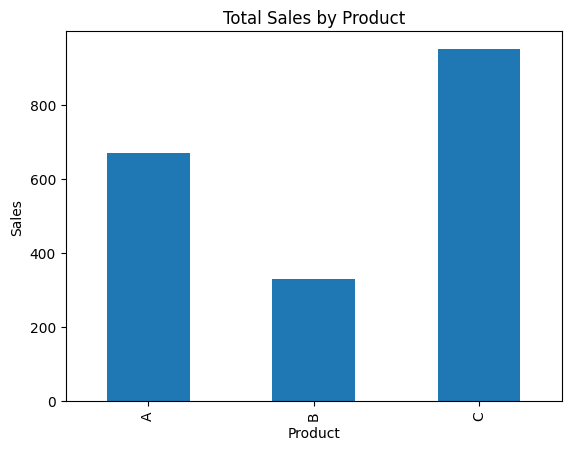

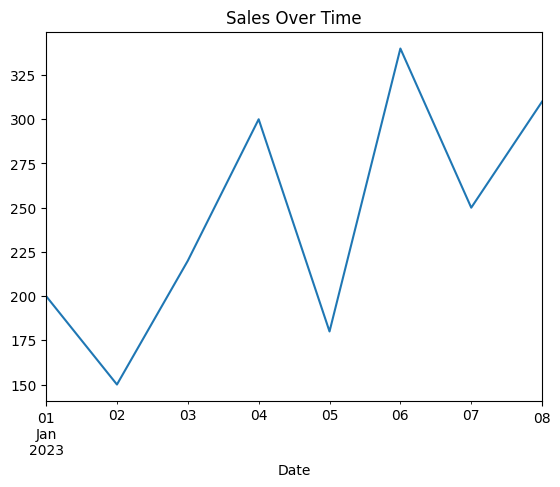

Product    A    B    C
Region                
East       0    0  950
North    670    0    0
South      0  150    0
West       0  180    0
             Sales  Quantity
Sales     1.000000  0.898629
Quantity  0.898629  1.000000


/tmp/ipykernel_3323/3219602550.py:31: FutureWarning: The provided callable <function sum at 0x7ff01998c720> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  pivot_table = df.pivot_table(values='Sales', index='Region', columns='Product', aggfunc=np.sum, fill_value=0)


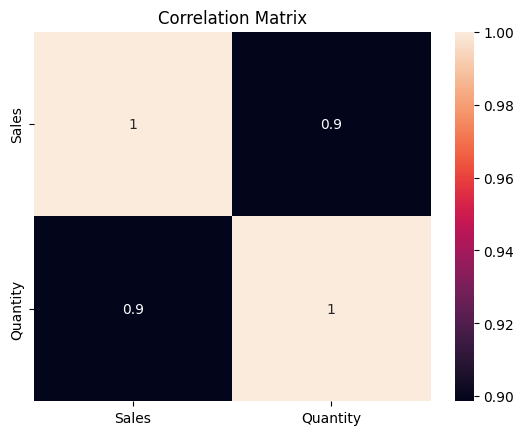

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    'Date': pd.date_range('2023-01-01', periods=8),
    'Product': ['A', 'B', 'A', 'C', 'B', 'C', 'A', 'C'],
    'Sales': [200, 150, 220, 300, 180, 340, 250, 310],
    'Quantity': [4, 3, 5, 6, 4, 8, 7, 6],
    'Region': ['North', 'South', 'North', 'East', 'West', 'East', 'North', 'East']
})

df.to_csv('sales-data.csv', index=False)
df = pd.read_csv('sales-data.csv', parse_dates=['Date'])

print(df.head())
print(df.isnull().sum())
print(df.select_dtypes(include=[np.number]).describe())

product_summary = df.groupby('Product')[['Sales', 'Quantity']].sum()
print(product_summary)

product_summary['Sales'].plot(kind='bar', title='Total Sales by Product')
plt.ylabel('Sales')
plt.show()

df.groupby('Date')['Sales'].sum().plot(title='Sales Over Time')
plt.show()

pivot_table = df.pivot_table(values='Sales', index='Region', columns='Product', aggfunc=np.sum, fill_value=0)
print(pivot_table)

correlation_matrix = df[['Sales', 'Quantity']].corr()
print(correlation_matrix)

sns.heatmap(correlation_matrix, annot=True)
plt.title('Correlation Matrix')
plt.show()